# Modelling: Weather-Conditioned Rocket Launch Success Predictor
Reproduces the interim baselines, then fixes the class imbalance (SMOTE, tuned Random Forest, tuned decision threshold) and saves the final model for the FastAPI backend.

Run top to bottom with the `venv` kernel. Outputs go to `../backend/model/` and `../reports/`.

In [1]:
import os, json, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib

from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV, cross_val_predict
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (precision_score, recall_score, f1_score, fbeta_score, accuracy_score,
                             average_precision_score, roc_auc_score, precision_recall_curve,
                             confusion_matrix, classification_report, ConfusionMatrixDisplay,
                             PrecisionRecallDisplay)
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import SMOTE

warnings.filterwarnings("ignore")
RANDOM_STATE = 42

DATA_FILE = "../data/merged_gcat_meteo.csv"
MODEL_DIR = "../backend/model"
FIG_DIR = "../reports/figures"
for d in (MODEL_DIR, FIG_DIR):
    os.makedirs(d, exist_ok=True)

NUM_COLS = ["temp_mean", "precipitation", "max_wind_speed"]
CAT_COLS = ["Launch_Site", "LV_Type", "Agency"]

## 1. Load data and build the target

In [2]:
df = pd.read_csv(DATA_FILE, low_memory=False)
print("Raw rows:", len(df))

missing = [c for c in NUM_COLS + CAT_COLS + ["FailCode"] if c not in df.columns]
if missing:
    print("Missing columns:", missing)
    print("Columns that look related:", [c for c in df.columns if any(k in c.lower() for k in ["agen", "org", "site", "type", "fail"])])
    raise SystemExit("Fix NUM_COLS / CAT_COLS above to match your column names, then rerun.")

# keep only fully weather-enriched rows (no imputation, same policy as the interim report)
data = df.dropna(subset=NUM_COLS).copy()
for c in CAT_COLS:
    data[c] = data[c].astype(str).fillna("Unknown")

# target: 1 = failure/anomaly (FailCode present), 0 = success
data["target"] = data["FailCode"].notna().astype(int)
print("Modelling rows:", len(data))
print(data["target"].value_counts().rename({0: "Success", 1: "Failure/Anomaly"}))
print((data["target"].value_counts(normalize=True) * 100).round(2).to_dict())

Raw rows: 17063
Modelling rows: 13593
target
Success            12783
Failure/Anomaly      810
Name: count, dtype: int64
{0: 94.04, 1: 5.96}


## 2. Stratified 80/20 split (same as the interim report)

In [3]:
X = data[NUM_COLS + CAT_COLS]
y = data["target"]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)
print("Train:", X_train.shape, "| anomalies:", int(y_train.sum()))
print("Test :", X_test.shape,  "| anomalies:", int(y_test.sum()))

def metrics_row(name, y_true, prob, thr=0.5):
    pred = (prob >= thr).astype(int)
    return {
        "Model": name,
        "Threshold": round(float(thr), 3),
        "Accuracy": accuracy_score(y_true, pred),
        "Precision": precision_score(y_true, pred, zero_division=0),
        "Recall": recall_score(y_true, pred),
        "F1": f1_score(y_true, pred),
        "F2": fbeta_score(y_true, pred, beta=2),
        "PR-AUC": average_precision_score(y_true, prob),
        "ROC-AUC": roc_auc_score(y_true, prob),
    }
results = []

Train: (10874, 6) | anomalies: 648
Test : (2719, 6) | anomalies: 162


## 3. Reproduce the interim baselines
Full one-hot encoding of every category (about 1,288 columns), balanced class weights, no resampling.
You should land close to the report: Logistic Regression about 73% accuracy and 56% anomaly recall, Random Forest about 93% accuracy and 9% recall.

In [4]:
prep_full = ColumnTransformer([
    ("num", StandardScaler(), NUM_COLS),
    ("cat", OneHotEncoder(handle_unknown="ignore", drop="first"), CAT_COLS),
])

lr_base = ImbPipeline([("prep", prep_full),
                       ("clf", LogisticRegression(max_iter=1000, class_weight="balanced"))])
rf_base = ImbPipeline([("prep", prep_full),
                       ("clf", RandomForestClassifier(n_estimators=100, class_weight="balanced",
                                                      random_state=RANDOM_STATE, n_jobs=-1))])
for name, m in [("Logistic Regression (baseline)", lr_base), ("Random Forest (baseline)", rf_base)]:
    m.fit(X_train, y_train)
    prob = m.predict_proba(X_test)[:, 1]
    results.append(metrics_row(name, y_test, prob))
    print("=" * 60); print(name)
    print("Encoded columns:", m.named_steps["prep"].transform(X_test.head(1)).shape[1])
    print(classification_report(y_test, (prob >= 0.5).astype(int), target_names=["Success", "Anomaly"]))

Logistic Regression (baseline)
Encoded columns: 1209
              precision    recall  f1-score   support

     Success       0.96      0.74      0.84      2557
     Anomaly       0.12      0.56      0.20       162

    accuracy                           0.73      2719
   macro avg       0.54      0.65      0.52      2719
weighted avg       0.91      0.73      0.80      2719

Random Forest (baseline)
Encoded columns: 1209
              precision    recall  f1-score   support

     Success       0.94      0.99      0.96      2557
     Anomaly       0.27      0.08      0.12       162

    accuracy                           0.93      2719
   macro avg       0.61      0.53      0.54      2719
weighted avg       0.90      0.93      0.91      2719



## 4. Improved pipeline: rare categories grouped, SMOTE inside the pipeline
- `min_frequency=30` merges any site, vehicle or agency with fewer than 30 launches into one "infrequent" bucket. This cuts the column count sharply, which also makes SMOTE far more sensible than on 1,288 sparse dummies.
- SMOTE sits **inside** the pipeline, so it only ever sees training folds. Nothing leaks into validation or test data.

In [5]:
def make_prep():
    return ColumnTransformer([
        ("num", StandardScaler(), NUM_COLS),
        ("cat", OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=30), CAT_COLS),
    ])

n_cols = make_prep().fit(X_train).transform(X_train.head(5)).shape[1]
print("Encoded columns after grouping rare categories:", n_cols)

lr_g = ImbPipeline([("prep", make_prep()),
                    ("clf", LogisticRegression(max_iter=1000, class_weight="balanced"))])
rf_g = ImbPipeline([("prep", make_prep()),
                    ("clf", RandomForestClassifier(n_estimators=200, class_weight="balanced",
                                                   random_state=RANDOM_STATE, n_jobs=-1))])
rf_smote = ImbPipeline([("prep", make_prep()),
                        ("smote", SMOTE(random_state=RANDOM_STATE)),
                        ("clf", RandomForestClassifier(n_estimators=200, random_state=RANDOM_STATE, n_jobs=-1))])

for name, m in [("Logistic Regression (grouped)", lr_g),
                ("Random Forest (grouped)", rf_g),
                ("Random Forest + SMOTE", rf_smote)]:
    m.fit(X_train, y_train)
    results.append(metrics_row(name, y_test, m.predict_proba(X_test)[:, 1]))
pd.DataFrame(results).round(3)

Encoded columns after grouping rare categories: 186


,Model,Threshold,Accuracy,Precision,Recall,F1,F2,PR-AUC,ROC-AUC
0,Logistic Regression (baseline),0.5,0.730,0.121,0.562,0.199,0.325,0.166,0.719
1,Random Forest (baseline),0.5,0.932,0.271,0.080,0.124,0.093,0.134,0.703
2,Logistic Regression (grouped),0.5,0.616,0.099,0.673,0.173,0.312,0.152,0.713
3,Random Forest (grouped),0.5,0.929,0.218,0.074,0.111,0.085,0.115,0.690
4,Random Forest + SMOTE,0.5,0.887,0.128,0.154,0.140,0.148,0.104,0.687


## 5. Hyperparameter search (scored on PR-AUC, the right metric for a 94:6 split)

In [6]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
param_grid = {
    "clf__max_depth": [None, 15],
    "clf__min_samples_leaf": [1, 3],
    "clf__max_features": ["sqrt", 0.3],
}
grid = GridSearchCV(rf_smote, param_grid, scoring="average_precision", cv=cv, n_jobs=-1, verbose=1)
grid.fit(X_train, y_train)
print("Best params :", grid.best_params_)
print("Best CV PR-AUC:", round(grid.best_score_, 4))
best_model = grid.best_estimator_
pd.DataFrame(grid.cv_results_)[["params", "mean_test_score", "std_test_score"]].sort_values(
    "mean_test_score", ascending=False).head(6)

Fitting 5 folds for each of 8 candidates, totalling 40 fits
Best params : {'clf__max_depth': None, 'clf__max_features': 0.3, 'clf__min_samples_leaf': 3}
Best CV PR-AUC: 0.1498


,params,mean_test_score,std_test_score
3,"{'clf__max_depth': None, 'clf__max_features': ...",0.149816,0.022298
7,"{'clf__max_depth': 15, 'clf__max_features': 0....",0.146804,0.023147
1,"{'clf__max_depth': None, 'clf__max_features': ...",0.145219,0.019049
6,"{'clf__max_depth': 15, 'clf__max_features': 0....",0.144656,0.024720
4,"{'clf__max_depth': 15, 'clf__max_features': 's...",0.139581,0.023850
5,"{'clf__max_depth': 15, 'clf__max_features': 's...",0.138688,0.019906


## 6. Decision-threshold tuning
The threshold is chosen from **out-of-fold predictions on the training set only**, maximising F2 (recall weighted above precision, because missing a failure is costlier than a false alarm). The test set is used once, at the end.

In [7]:
oof = cross_val_predict(best_model, X_train, y_train, cv=cv, method="predict_proba", n_jobs=-1)[:, 1]
prec, rec, thr = precision_recall_curve(y_train, oof)
f2_curve = (5 * prec * rec) / (4 * prec + rec + 1e-12)
best_thr = float(thr[np.argmax(f2_curve[:-1])])
print("Chosen threshold (max F2 on out-of-fold training predictions):", round(best_thr, 3))

test_prob = best_model.predict_proba(X_test)[:, 1]
results.append(metrics_row("RF + SMOTE (default 0.5)", y_test, test_prob, 0.5))
results.append(metrics_row("RF + SMOTE + tuned threshold (FINAL)", y_test, test_prob, best_thr))
results_df = pd.DataFrame(results).round(3)
results_df.to_csv("../reports/model_comparison.csv", index=False)
results_df

Chosen threshold (max F2 on out-of-fold training predictions): 0.167


,Model,Threshold,Accuracy,Precision,Recall,F1,F2,PR-AUC,ROC-AUC
0,Logistic Regression (baseline),0.500,0.730,0.121,0.562,0.199,0.325,0.166,0.719
1,Random Forest (baseline),0.500,0.932,0.271,0.080,0.124,0.093,0.134,0.703
2,Logistic Regression (grouped),0.500,0.616,0.099,0.673,0.173,0.312,0.152,0.713
3,Random Forest (grouped),0.500,0.929,0.218,0.074,0.111,0.085,0.115,0.690
4,Random Forest + SMOTE,0.500,0.887,0.128,0.154,0.140,0.148,0.104,0.687
5,RF + SMOTE (default 0.5),0.500,0.882,0.130,0.173,0.149,0.162,0.122,0.705
6,RF + SMOTE + tuned threshold (FINAL),0.167,0.701,0.119,0.630,0.200,0.339,0.122,0.705


## 7. Final model report

              precision    recall  f1-score   support

     Success       0.97      0.71      0.82      2557
     Anomaly       0.12      0.63      0.20       162

    accuracy                           0.70      2719
   macro avg       0.54      0.67      0.51      2719
weighted avg       0.92      0.70      0.78      2719

Confusion matrix [rows = actual, cols = predicted]:
[[1803  754]
 [  60  102]]


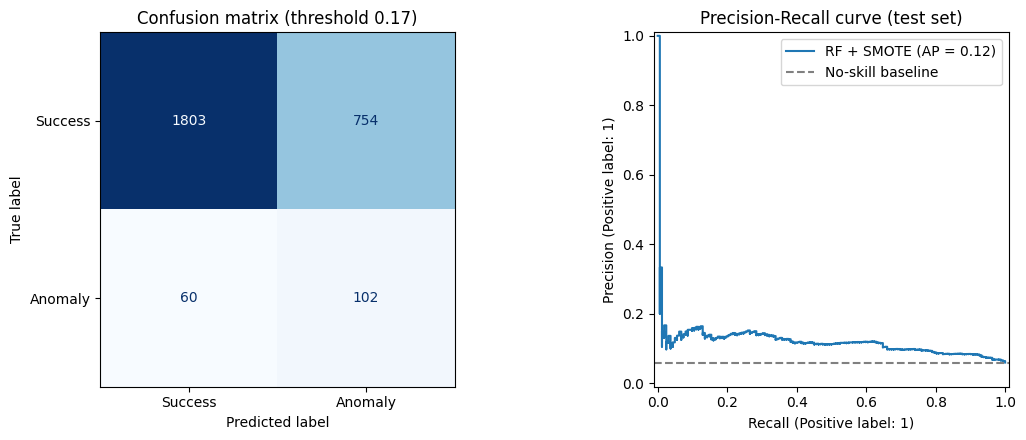

In [8]:
final_pred = (test_prob >= best_thr).astype(int)
print(classification_report(y_test, final_pred, target_names=["Success", "Anomaly"]))
print("Confusion matrix [rows = actual, cols = predicted]:")
print(confusion_matrix(y_test, final_pred))

fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
ConfusionMatrixDisplay.from_predictions(y_test, final_pred, display_labels=["Success", "Anomaly"],
                                        cmap="Blues", ax=ax[0], colorbar=False)
ax[0].set_title(f"Confusion matrix (threshold {best_thr:.2f})")
PrecisionRecallDisplay.from_predictions(y_test, test_prob, ax=ax[1], name="RF + SMOTE")
ax[1].axhline(y_test.mean(), ls="--", color="grey", label="No-skill baseline")
ax[1].set_title("Precision-Recall curve (test set)"); ax[1].legend()
plt.tight_layout(); plt.savefig(f"{FIG_DIR}/final_model_evaluation.png", dpi=200); plt.show()

No-skill PR-AUC (anomaly rate in test set): 0.06


,Model,Threshold,Accuracy,Precision,Recall,F1,F2,PR-AUC,ROC-AUC
0,Logistic Regression (baseline),0.500,0.730,0.121,0.562,0.199,0.325,0.166,0.719
1,Random Forest (baseline),0.500,0.932,0.271,0.080,0.124,0.093,0.134,0.703
2,Logistic Regression (grouped),0.500,0.616,0.099,0.673,0.173,0.312,0.152,0.713
3,Random Forest (grouped),0.500,0.929,0.218,0.074,0.111,0.085,0.115,0.690
4,Random Forest + SMOTE,0.500,0.887,0.128,0.154,0.140,0.148,0.104,0.687
5,RF + SMOTE (default 0.5),0.500,0.882,0.130,0.173,0.149,0.162,0.122,0.705
6,RF + SMOTE + tuned threshold (FINAL),0.167,0.701,0.119,0.630,0.200,0.339,0.122,0.705
7,Logistic Regression (grouped) + tuned threshold,0.547,0.679,0.105,0.580,0.177,0.304,0.152,0.713
8,"Random Forest (balanced, no SMOTE) + tuned thr...",0.045,0.713,0.113,0.556,0.188,0.311,0.115,0.690


No-skill PR-AUC (anomaly rate in train set): 0.06


,Feature set,CV PR-AUC,PR-AUC std,CV ROC-AUC
0,Site + vehicle + agency only,0.150,0.022,0.731
1,Weather only,0.073,0.008,0.563
2,Weather + site + vehicle + agency,0.146,0.016,0.725
3,Above + launch year,0.173,0.023,0.743


,variable,PR-AUC drop when shuffled,std
4,LV_Type,0.0203,0.0098
5,Agency,0.0169,0.0058
2,max_wind_speed,0.0078,0.0075
1,precipitation,0.0051,0.0063
3,Launch_Site,0.0029,0.0089
0,temp_mean,-0.0090,0.0074


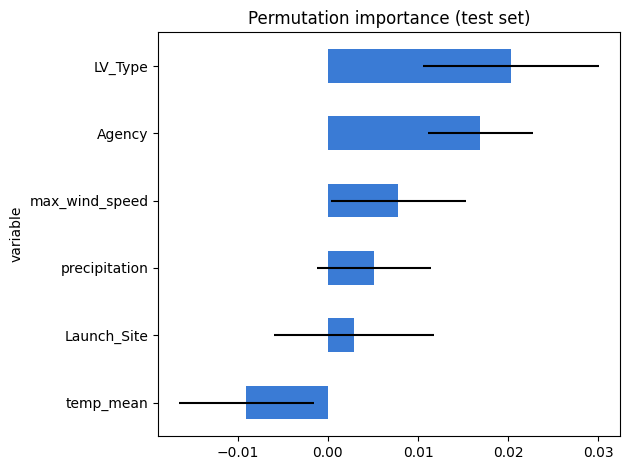

In [12]:
from sklearn.base import clone
from sklearn.model_selection import cross_val_score
from sklearn.inspection import permutation_importance

# A. Fair comparison: tune the threshold for every model
def tune_and_score(model, name):
    oof = cross_val_predict(model, X_train, y_train, cv=cv, method="predict_proba", n_jobs=-1)[:, 1]
    p, r, t = precision_recall_curve(y_train, oof)
    f2 = (5 * p * r) / (4 * p + r + 1e-12)
    thr = float(t[np.argmax(f2[:-1])])
    model.fit(X_train, y_train)
    return metrics_row(name + " + tuned threshold", y_test, model.predict_proba(X_test)[:, 1], thr)

fair = [tune_and_score(clone(lr_g), "Logistic Regression (grouped)"),
        tune_and_score(clone(rf_g), "Random Forest (balanced, no SMOTE)")]
full_df = pd.concat([results_df, pd.DataFrame(fair).round(3)], ignore_index=True)
full_df.to_csv("../reports/model_comparison_full.csv", index=False)
print("No-skill PR-AUC (anomaly rate in test set):", round(float(y_test.mean()), 3))
display(full_df)

# B. Does weather add signal? Ablation with cross-validated PR-AUC
def prep_for(num, cat):
    parts = []
    if num: parts.append(("num", StandardScaler(), num))
    if cat: parts.append(("cat", OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=30), cat))
    return ColumnTransformer(parts)

def cv_scores(num, cat, frame):
    m = ImbPipeline([("prep", prep_for(num, cat)),
                     ("clf", RandomForestClassifier(n_estimators=200, min_samples_leaf=3, class_weight="balanced",
                                                    random_state=RANDOM_STATE, n_jobs=-1))])
    cols = num + cat
    pr = cross_val_score(m, frame[cols], y_train, cv=cv, scoring="average_precision", n_jobs=-1)
    roc = cross_val_score(m, frame[cols], y_train, cv=cv, scoring="roc_auc", n_jobs=-1)
    return pr.mean(), pr.std(), roc.mean()

train_frame = X_train.copy()
year = pd.to_datetime(data["Launch_Date"], errors="coerce").dt.year
train_frame["Launch_Year"] = year.loc[X_train.index].fillna(year.median())

ablation = []
for label, num, cat in [("Site + vehicle + agency only", [], CAT_COLS),
                        ("Weather only", NUM_COLS, []),
                        ("Weather + site + vehicle + agency", NUM_COLS, CAT_COLS),
                        ("Above + launch year", NUM_COLS + ["Launch_Year"], CAT_COLS)]:
    pr, sd, roc = cv_scores(num, cat, train_frame)
    ablation.append({"Feature set": label, "CV PR-AUC": round(pr, 3), "PR-AUC std": round(sd, 3), "CV ROC-AUC": round(roc, 3)})
ablation_df = pd.DataFrame(ablation)
ablation_df.to_csv("../reports/feature_ablation.csv", index=False)
print("No-skill PR-AUC (anomaly rate in train set):", round(float(y_train.mean()), 3))
display(ablation_df)

# C. Permutation importance on the test set
pi = permutation_importance(best_model, X_test, y_test, scoring="average_precision",
                            n_repeats=10, random_state=RANDOM_STATE, n_jobs=-1)
perm = (pd.DataFrame({"variable": X_test.columns, "PR-AUC drop when shuffled": pi.importances_mean,
                      "std": pi.importances_std})
        .sort_values("PR-AUC drop when shuffled", ascending=False))
perm.round(4).to_csv("../reports/permutation_importance.csv", index=False)
display(perm.round(4))
ax = perm.set_index("variable")["PR-AUC drop when shuffled"].plot.barh(
    xerr=perm.set_index("variable")["std"], color="#3A7BD5")
ax.invert_yaxis(); ax.set_title("Permutation importance (test set)")
plt.tight_layout(); plt.savefig(f"{FIG_DIR}/permutation_importance.png", dpi=200); plt.show()

## 8. Interpretation: which features drive the prediction?

LV_Type           32.45
Agency            18.93
Launch_Site       13.47
max_wind_speed    12.85
temp_mean         11.70
precipitation     10.60
dtype: float64

Weather features combined: 35.2% of total importance


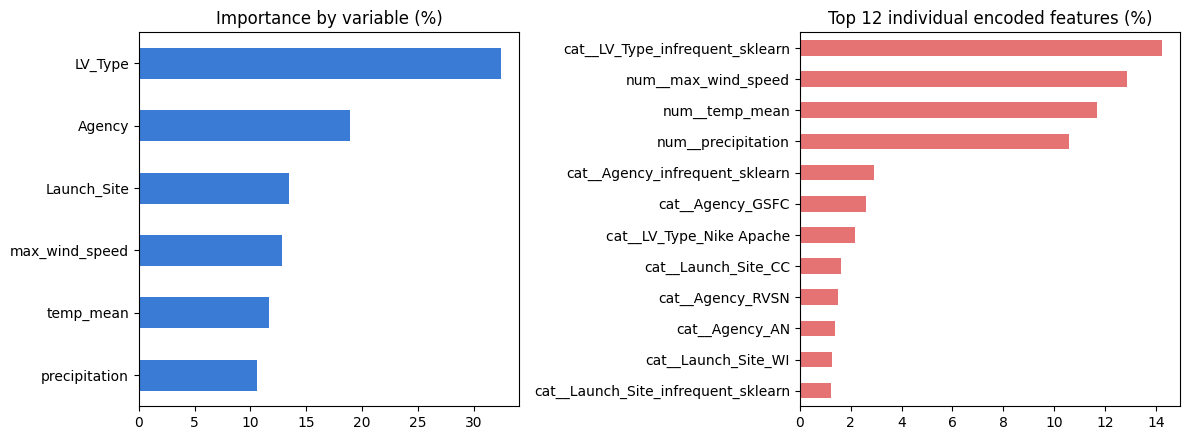

In [13]:
rf = best_model.named_steps["clf"]
names = best_model.named_steps["prep"].get_feature_names_out()
imp = pd.Series(rf.feature_importances_, index=names)

def group_of(n):
    n = n.replace("num__", "").replace("cat__", "")
    for c in CAT_COLS:
        if n.startswith(c + "_"):
            return c
    return n

grouped = imp.groupby([group_of(n) for n in imp.index]).sum().sort_values(ascending=False)
print((grouped * 100).round(2))
weather_share = grouped[NUM_COLS].sum() * 100
print(f"\nWeather features combined: {weather_share:.1f}% of total importance")

fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
(grouped * 100).plot.barh(ax=ax[0], color="#3A7BD5"); ax[0].invert_yaxis()
ax[0].set_title("Importance by variable (%)")
(imp.sort_values(ascending=False).head(12) * 100).plot.barh(ax=ax[1], color="#E57373"); ax[1].invert_yaxis()
ax[1].set_title("Top 12 individual encoded features (%)")
plt.tight_layout(); plt.savefig(f"{FIG_DIR}/feature_importance.png", dpi=200); plt.show()

## 9. Save everything the FastAPI backend needs

In [10]:
site_stats = (data.groupby("Launch_Site")["target"].agg(launches="size", anomalies="sum")
              .assign(anomaly_rate=lambda d: (d.anomalies / d.launches * 100).round(2))
              .sort_values("launches", ascending=False).head(10).reset_index())

eda_stats = {
    "total_records": int(len(data)),
    "success": int((data.target == 0).sum()),
    "anomaly": int((data.target == 1).sum()),
    "anomaly_pct": round(float(data.target.mean() * 100), 2),
    "weather_means_by_outcome": (data.groupby(data.target.map({0: "Success", 1: "Anomaly"}))[NUM_COLS]
                                 .mean().round(2).to_dict(orient="index")),
    "top_sites": site_stats.to_dict(orient="records"),
}
final_metrics = results_df[results_df.Model.str.contains("FINAL")].iloc[0].to_dict()

bundle = {
    "model": best_model,
    "threshold": best_thr,
    "num_cols": NUM_COLS,
    "cat_cols": CAT_COLS,
    "known_categories": {c: sorted(X_train[c].unique().tolist()) for c in CAT_COLS},
}
joblib.dump(bundle, f"{MODEL_DIR}/rocket_model.joblib", compress=3)

meta = {
    "metrics": final_metrics,
    "best_params": {k: (None if v is None else v) for k, v in grid.best_params_.items()},
    "feature_importance_by_variable": {k: round(float(v) * 100, 2) for k, v in grouped.items()},
    "top_encoded_features": {k: round(float(v) * 100, 2) for k, v in imp.sort_values(ascending=False).head(15).items()},
    "eda_stats": eda_stats,
}
with open(f"{MODEL_DIR}/metadata.json", "w") as f:
    json.dump(meta, f, indent=2, default=str)

print("Saved:", os.listdir(MODEL_DIR))
print("Model file size (MB):", round(os.path.getsize(f"{MODEL_DIR}/rocket_model.joblib") / 1e6, 2))

Saved: ['metadata.json', 'rocket_model.joblib']
Model file size (MB): 8.82


## 10. Sanity check: load the saved model like the API will

In [11]:
b = joblib.load(f"{MODEL_DIR}/rocket_model.joblib")
example = pd.DataFrame([{
    "temp_mean": 18.0, "precipitation": 0.0, "max_wind_speed": 12.0,
    "Launch_Site": X_train["Launch_Site"].iloc[0],
    "LV_Type": X_train["LV_Type"].iloc[0],
    "Agency": X_train["Agency"].iloc[0],
}])
p = float(b["model"].predict_proba(example)[0, 1])
print("Anomaly risk:", round(p, 4), "| flagged:", p >= b["threshold"])

Anomaly risk: 0.002 | flagged: False
